---

# MELT REVIEW

---


100 empleados de una empresa tech con evaluaciones de habilidades. Tiene 14 columnas organizadas en tres grupos semánticos, y eso es la clave del diseño para practicar `melt()`.

Columnas identificadoras (candidatas a `id_vars`): <span style='color:royalblue'>**employee_id, name, department, seniority**</span>

`Grupo 1` — Skills técnicos y blandos (7 columnas): <span style='color:crimson'>**python, sql, excel, tableau, communication, leadership, problem_solving**</span> — scores del 1 al 10

`Grupo 2` — Métricas generales (3 columnas): <span style='color:crimson'>**years_experience, projects_completed, satisfaction**</span>

Lo que hace este dataset útil para `melt()` es que te obliga a practicar cada parámetro:

- `id_vars` → ['employee_id', 'name', 'department', 'seniority'] — las columnas que permanecen fijas
- `value_vars` → Aquí está lo interesante: si no lo especificas, Pandas meltea todas las columnas no listadas en id_vars (*skills + métricas mezcladas, lo cual no tiene sentido semántico*). Para hacer un melt limpio, necesitas seleccionar solo las 7 skills
- `var_name` → El default `'variable'` no dice nada. Necesitas renombrarlo a <span style='color:orange'>**'skill'**</span>
- `value_name` → El default `'value'` tampoco. Necesitas <span style='color:orange'>**'score'`**</span>
- `ignore_index` → Prueba con True vs False para ver cómo cambia el index del resultado

<br>

>---
>
>**La diferencia clave con el dataset (wide_to_long) es que aquí las columnas no tienen un patrón stub+sufijo (revenue_Q1, revenue_Q2...) — son nombres independientes (python, sql, excel...). Esa es exactamente la distinción entre cuándo usar `melt()` y cuándo usar `wide_to_long()`.**
>
>---

<br>

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Use the "on_bad_lines='warn'" or "on_bad_lines='skip'" to keep working. Otherwise will raise an error
# ----------------------------------------------------------------------
#df_error = pd.read_csv('Resources/books.csv', on_bad_lines='warn')
#df_error

In [3]:
df = pd.read_csv('employee_skills.csv', )
df.head()

,employee_id,name,department,seniority,python,sql,excel,tableau,communication,leadership,problem_solving,years_experience,projects_completed,satisfaction
0,EMP-001,Emilio Gutiérrez,Sales,Junior,1.7,1.8,7.4,4.6,6.9,4.7,4.5,3,6,7.3
1,EMP-002,Lucía Martínez,Product,Mid,3.8,5.6,4.8,5.4,7.0,6.7,7.6,3,13,6.6
2,EMP-003,Daniel Ramírez,HR,Junior,1.8,2.8,3.6,2.0,6.0,4.7,6.2,3,10,2.9
3,EMP-004,Alejandro Vargas,Sales,Junior,1.5,3.3,4.8,4.0,6.2,4.8,5.8,2,11,9.0
4,EMP-005,Sara Reyes,HR,Mid,1.4,2.8,6.5,5.1,8.0,7.5,6.3,4,14,6.3


In [4]:
# Working only with "id_vars" and ['employee_id', 'name']

# NOTE: All the rest of the columns become part of the 'variable' and 'value' columns
(df.melt(id_vars=['employee_id', 'name',])
   .sort_values(by=['employee_id', 'variable'], 
                ignore_index=True))

,employee_id,name,variable,value
0,EMP-001,Emilio Gutiérrez,communication,6.9
1,EMP-001,Emilio Gutiérrez,department,Sales
2,EMP-001,Emilio Gutiérrez,excel,7.4
3,EMP-001,Emilio Gutiérrez,leadership,4.7
4,EMP-001,Emilio Gutiérrez,problem_solving,4.5
...,...,...,...,...
1195,EMP-100,Fernanda Ramírez,satisfaction,6.1
1196,EMP-100,Fernanda Ramírez,seniority,Junior
1197,EMP-100,Fernanda Ramírez,sql,2.1
1198,EMP-100,Fernanda Ramírez,tableau,2.0


In [5]:
# Working only with "id_vars" -> ['employee_id', 'name', 'department', 'seniority']

# NOTE: Note that the rest of the columns not included in "id_vars" form part
#       of the 'variable' and 'value' columns 
(df.melt(id_vars=['employee_id', 'name', 'department', 'seniority'])
   .sort_values(by=['employee_id', 'department'], ignore_index=True))

,employee_id,name,department,seniority,variable,value
0,EMP-001,Emilio Gutiérrez,Sales,Junior,python,1.7
1,EMP-001,Emilio Gutiérrez,Sales,Junior,sql,1.8
2,EMP-001,Emilio Gutiérrez,Sales,Junior,excel,7.4
3,EMP-001,Emilio Gutiérrez,Sales,Junior,tableau,4.6
4,EMP-001,Emilio Gutiérrez,Sales,Junior,communication,6.9
...,...,...,...,...,...,...
995,EMP-100,Fernanda Ramírez,HR,Junior,leadership,4.6
996,EMP-100,Fernanda Ramírez,HR,Junior,problem_solving,5.3
997,EMP-100,Fernanda Ramírez,HR,Junior,years_experience,3.0
998,EMP-100,Fernanda Ramírez,HR,Junior,projects_completed,9.0


<br>

---

## Skills por grupo
<br>

In [6]:
skill_cols = ['python', 'sql', 'excel', 'tableau', 
              'communication', 'leadership', 'problem_solving']
# ---------------------------------------------------------------------
df1 = (df
    .melt(id_vars=['employee_id', 'name', 'department', 'seniority'],
          value_vars=skill_cols,
          var_name='skill', 
          value_name='score',
          ignore_index=False)
    .sort_values(by=['employee_id', 'department'])
)

df1.head(20)

,employee_id,name,department,seniority,skill,score
0,EMP-001,Emilio Gutiérrez,Sales,Junior,python,1.7
0,EMP-001,Emilio Gutiérrez,Sales,Junior,sql,1.8
0,EMP-001,Emilio Gutiérrez,Sales,Junior,excel,7.4
0,EMP-001,Emilio Gutiérrez,Sales,Junior,tableau,4.6
0,EMP-001,Emilio Gutiérrez,Sales,Junior,communication,6.9
0,EMP-001,Emilio Gutiérrez,Sales,Junior,leadership,4.7
0,EMP-001,Emilio Gutiérrez,Sales,Junior,problem_solving,4.5
1,EMP-002,Lucía Martínez,Product,Mid,python,3.8
1,EMP-002,Lucía Martínez,Product,Mid,sql,5.6
1,EMP-002,Lucía Martínez,Product,Mid,excel,4.8


In [7]:
df1 = (df
    .melt(id_vars=['employee_id', 'name', 'department', 'seniority'],
          value_vars=skill_cols,
          var_name='skill', 
          value_name='score', #ignore_index=True
         )
    .sort_values(by=['employee_id'], ignore_index=True)
)

df1.head(20)

,employee_id,name,department,seniority,skill,score
0,EMP-001,Emilio Gutiérrez,Sales,Junior,python,1.7
1,EMP-001,Emilio Gutiérrez,Sales,Junior,tableau,4.6
2,EMP-001,Emilio Gutiérrez,Sales,Junior,communication,6.9
3,EMP-001,Emilio Gutiérrez,Sales,Junior,leadership,4.7
4,EMP-001,Emilio Gutiérrez,Sales,Junior,sql,1.8
5,EMP-001,Emilio Gutiérrez,Sales,Junior,problem_solving,4.5
6,EMP-001,Emilio Gutiérrez,Sales,Junior,excel,7.4
7,EMP-002,Lucía Martínez,Product,Mid,tableau,5.4
8,EMP-002,Lucía Martínez,Product,Mid,excel,4.8
9,EMP-002,Lucía Martínez,Product,Mid,python,3.8


<br><br>

---

## DataFrames con Formato 'Wide' VS. 'Long'?

<br>

<br>

---

### Grouped Bars

In [8]:
df.head(2)

,employee_id,name,department,seniority,python,sql,excel,tableau,communication,leadership,problem_solving,years_experience,projects_completed,satisfaction
0,EMP-001,Emilio Gutiérrez,Sales,Junior,1.7,1.8,7.4,4.6,6.9,4.7,4.5,3,6,7.3
1,EMP-002,Lucía Martínez,Product,Mid,3.8,5.6,4.8,5.4,7.0,6.7,7.6,3,13,6.6


In [9]:
# Creamos el dataset para el chart con Matplotlib
df_plt1 = df.groupby('department')[skill_cols].mean()
df_plt1

,python,sql,excel,tableau,communication,leadership,problem_solving
department,,,,,,,
Engineering,7.131579,6.268421,4.047368,3.136842,4.968421,3.763158,7.336842
HR,2.309375,3.243750,6.271875,3.765625,7.884375,6.778125,6.175000
Marketing,2.900000,3.664706,5.788235,6.770588,7.988235,4.858824,5.029412
Product,5.006667,4.880000,5.233333,5.573333,7.053333,6.093333,7.946667
Sales,2.188235,2.541176,7.235294,4.900000,7.782353,6.323529,5.611765


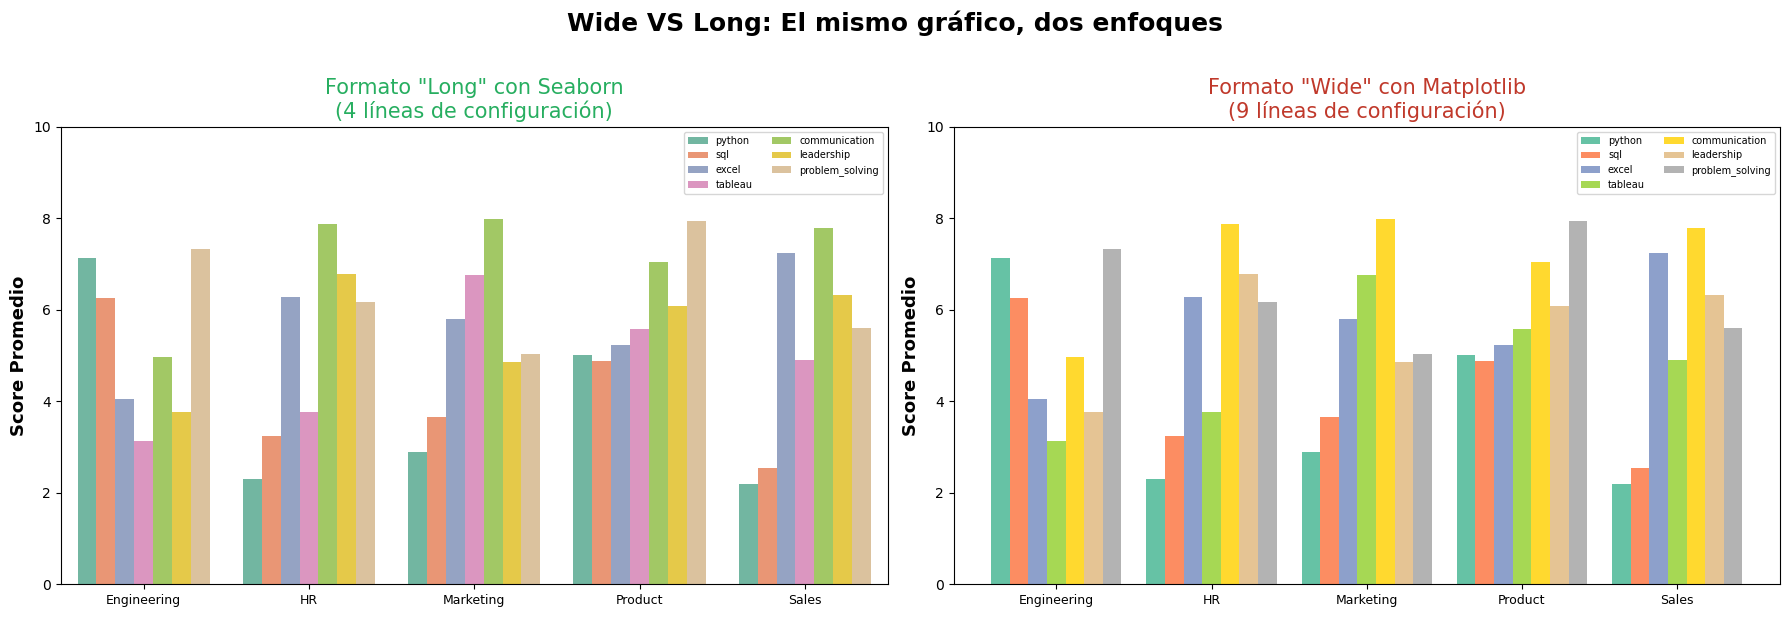

In [10]:
# Graficando con formato Wide VS Long 
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wide VS Long: El mismo gráfico, dos enfoques', fontsize=18, fontweight='bold', y=1.02)

# --------------------------------------------------------------------------------------------------
# Chart Izquierdo - Seaborn: Utilizando formato Long
x_lab_sort = sorted(df1.department.unique())

ax = axes[0]
sns.barplot(data=df1, x='department', y='score', hue='skill', ax=ax, palette='Set2', 
            errorbar=None, hue_order=skill_cols, order=x_lab_sort)

ax.set_ylim(0, 10)
ax.tick_params(axis='x', labelsize=9)

ax.set_ylabel('Score Promedio', fontsize=13, fontweight='bold')
ax.set_title('Formato "Long" con Seaborn\n(4 líneas de configuración)', fontsize=15, color='#27ae60')
ax.set_xlabel('')

ax.legend(fontsize=7, ncol=2)

# --------------------------------------------------------------------------------------------------
# Chart Derecho - Matplotlib: Utilizando formato Wide
ax = axes[1]
x = np.arange(len(df_plt1.index))
width = 0.12
colors = plt.cm.Set2(np.linspace(0, 1, len(skill_cols)))

for i, skill in enumerate(skill_cols):
    ax.bar(x + i * width, df_plt1[skill], width=width,
           label=skill, color=colors[i])

ax.set_xticks(x + width*3)
ax.set_xticklabels(df_plt1.index, fontsize=9)
ax.set_ylim(0, 10)

ax.set_ylabel('Score Promedio', fontsize=13, fontweight='bold')
ax.set_title('Formato "Wide" con Matplotlib\n(9 líneas de configuración)', fontsize=15, color='#c0392b')

ax.legend(fontsize=7, ncol=2)
# --------------------------------------------------------------------------------------------------
plt.tight_layout()
plt.show()
plt.close()

<br>

---

### Box Plots

In [22]:
df.head(2)

,employee_id,name,department,seniority,python,sql,excel,tableau,communication,leadership,problem_solving,years_experience,projects_completed,satisfaction
0,EMP-001,Emilio Gutiérrez,Sales,Junior,1.7,1.8,7.4,4.6,6.9,4.7,4.5,3,6,7.3
1,EMP-002,Lucía Martínez,Product,Mid,3.8,5.6,4.8,5.4,7.0,6.7,7.6,3,13,6.6


In [27]:
df.python.head(10)

0    1.7
1    3.8
2    1.8
3    1.5
4    1.4
5    5.4
6    8.1
7    5.8
8    2.7
9    2.2
Name: python, dtype: float64

In [34]:
# El DataFrame para Matplotlib necesita una lista por cada Skill
# NOTA: ax.boxplot(), espera una LISTA DE ARRAYS, no un DataFrame
df_plt2 = list(df[skill].values for skill in skill_cols)
df_plt2[:1]

[array([1.7, 3.8, 1.8, 1.5, 1.4, 5.4, 8.1, 5.8, 2.7, 2.2, 1. , 9.1, 3.2,
        4.9, 2.4, 1. , 7.5, 1. , 1.4, 3.5, 7.5, 4.1, 1.3, 4.9, 6.1, 3.3,
        1.2, 2.3, 3. , 6.1, 3.6, 3. , 3.8, 7. , 4.9, 2.4, 8.8, 1. , 4.3,
        4.7, 1.1, 2.1, 1.3, 5. , 2.5, 2.5, 1.8, 7.6, 6.9, 6. , 7.4, 6. ,
        2.7, 3.3, 4.1, 1. , 6.5, 5.1, 6.2, 2.4, 6.5, 9. , 1.6, 7.9, 5. ,
        2.4, 3.3, 2.8, 5.3, 3.2, 3.4, 5.5, 2.1, 3.5, 3. , 1.5, 6.2, 1.5,
        6.3, 1.2, 2.1, 4.3, 3.2, 4.1, 3.4, 1.5, 4.4, 1. , 1. , 1. , 1. ,
        2.8, 4.2, 2. , 6. , 2.3, 4.8, 1.7, 2.8, 2. ])]

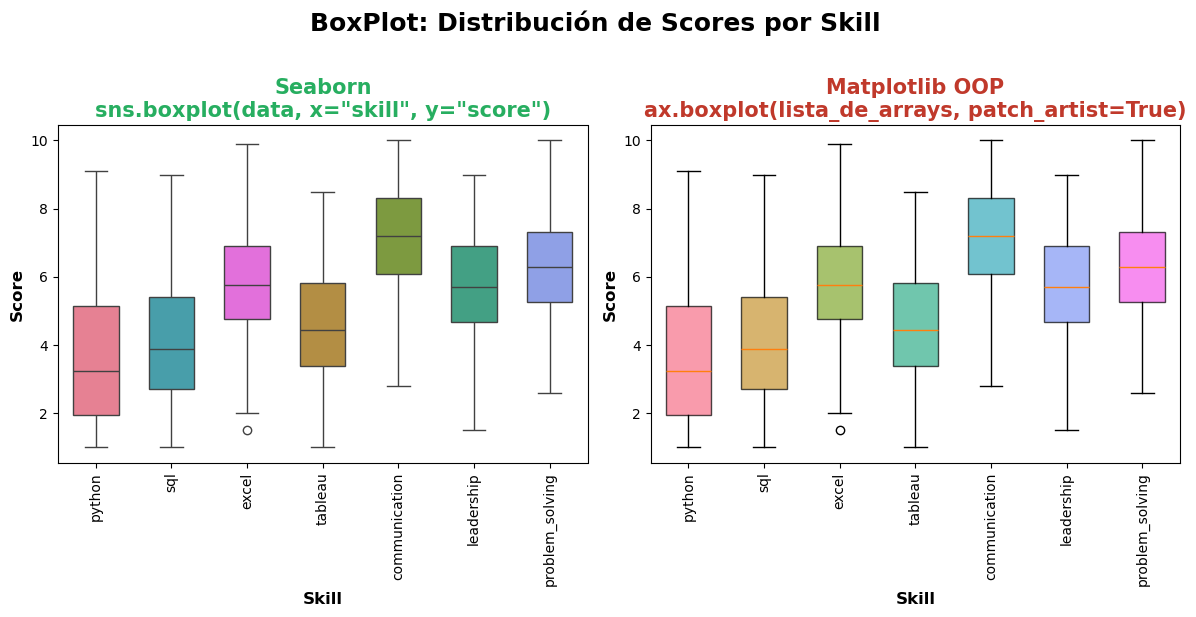

In [47]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))
fig.suptitle('BoxPlot: Distribución de Scores por Skill',
             fontsize=18, fontweight='bold', y=1.02)
# ------------------------------------------------------------------------
# Chart Izquierdo: Seaborn
ax = axes[0]
sns.boxplot(data=df1, x='skill', y='score', hue='skill', order=skill_cols,
            palette='husl', ax=ax, legend=False, width=0.6)
ax.tick_params(axis='x', rotation=90)

ax.set_title('Seaborn\nsns.boxplot(data, x="skill", y="score")', 
             fontsize=15, fontweight='bold', color='#27ae60')
ax.set_xlabel('Skill', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')


# ------------------------------------------------------------------------
# Chart Derecho: Matplotlib
ax = axes[1]
bp = ax.boxplot(df_plt2, patch_artist= True, # permite rellenar con color
                tick_labels=skill_cols,
                widths=0.6)

# Coloreamos manualmente cada caja
colors = sns.color_palette('husl', n_colors=len(skill_cols))
for patch, color, in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title('Matplotlib OOP\nax.boxplot(lista_de_arrays, patch_artist=True)',
             fontsize=15, fontweight='bold', color='#c0392b')
ax.set_xlabel('Skill', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=90)
# ------------------------------------------------------------------------
plt.tight_layout()
plt.show()


In [23]:
df1.head()

,employee_id,name,department,seniority,skill,score
0,EMP-001,Emilio Gutiérrez,Sales,Junior,python,1.7
1,EMP-001,Emilio Gutiérrez,Sales,Junior,tableau,4.6
2,EMP-001,Emilio Gutiérrez,Sales,Junior,communication,6.9
3,EMP-001,Emilio Gutiérrez,Sales,Junior,leadership,4.7
4,EMP-001,Emilio Gutiérrez,Sales,Junior,sql,1.8


<br>

---

### Violin Plots

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.violinplot(data=df, x='skill', y='score', palette='mutted',
               hue='skill', inner='quartile', ax=ax)

ax.set_title('

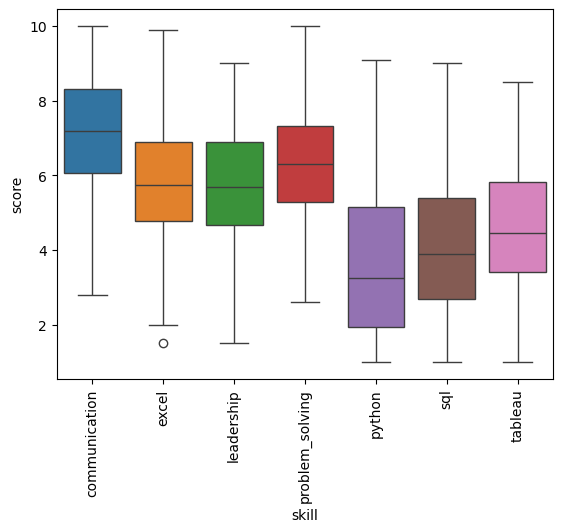

In [12]:
sns.boxplot(data=df1, x='skill', y='score', hue=df1.skill)
plt.xticks(rotation=90)
plt.show()

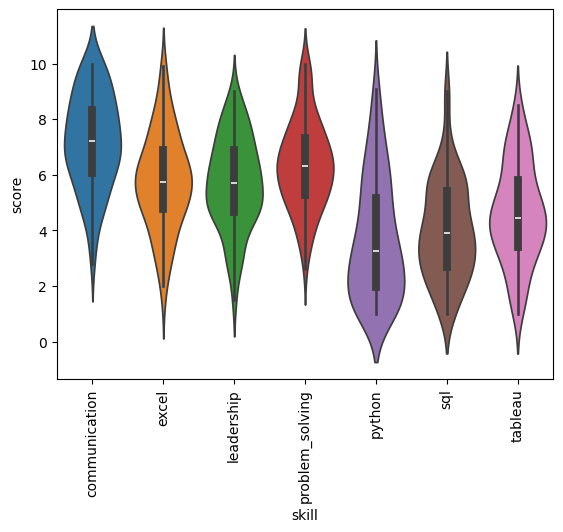

In [18]:
sns.violinplot(data=df1, x='skill', y='score', hue=df1.skill)
plt.xticks(rotation=90)
plt.show()

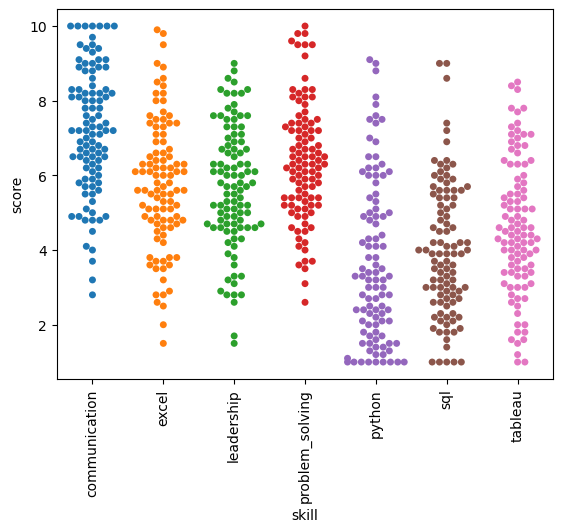

In [19]:
sns.swarmplot(data=df1, x='skill', y='score', hue=df1.skill)
plt.xticks(rotation=90)
plt.show()

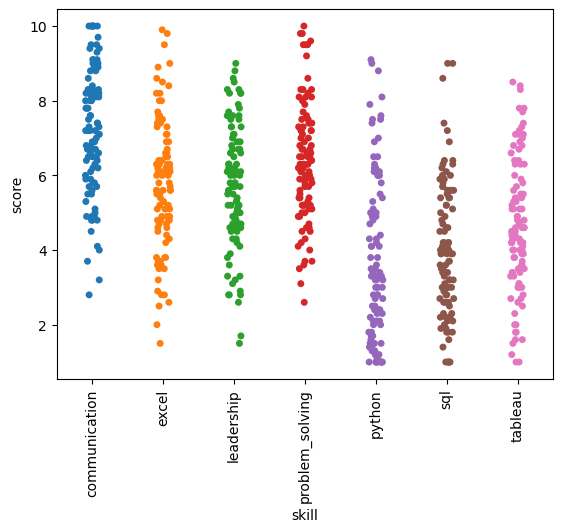

In [20]:
sns.stripplot(data=df1, x='skill', y='score', hue=df1.skill)
plt.xticks(rotation=90)
plt.show()

---

<br>

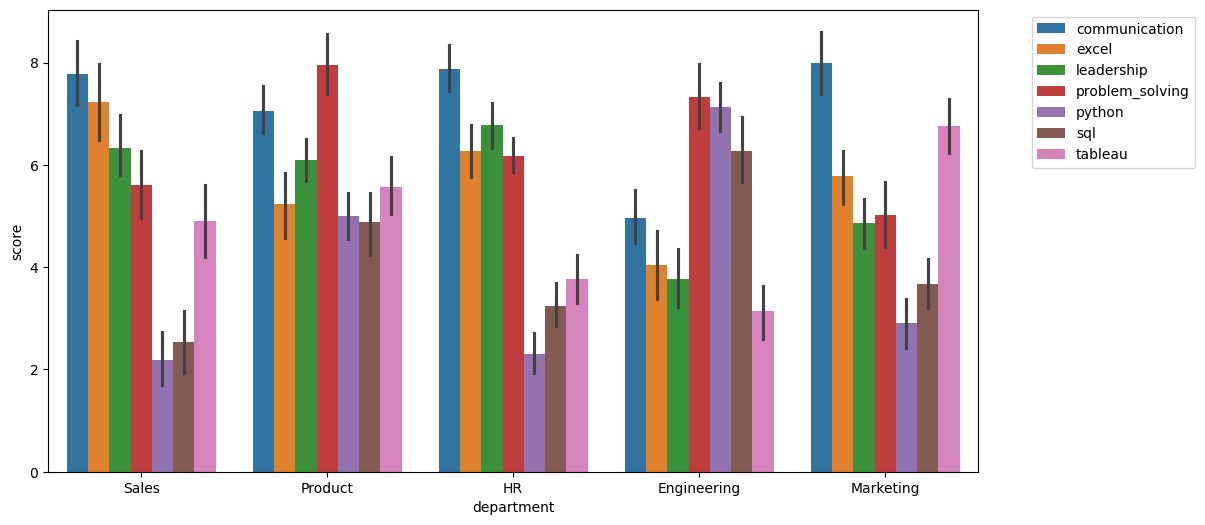

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df1, x='department', y='score', hue='skill')
plt.legend(bbox_to_anchor=(1.05, 1))
plt.show()

In [21]:
sns.catplot(df=df1, x='skill', y='score')
plt.show()

ValueError: Could not interpret value `skill` for `x`. Value is a string, but `data` was not passed.

<br>

---

## Soft Skills por Grupo
<br>

In [8]:
df2 = (df
    .melt(id_vars=['employee_id', 'name', 'department', 'seniority'],
          value_vars=['years_experience', 'projects_completed', 'satisfaction'],
          var_name='metric',
          value_name='score', 
          ignore_index=False)
    .sort_values(by=['employee_id', 'metric'])
)
df2.head(7)

,employee_id,name,department,seniority,metric,score
0,EMP-001,Emilio Gutiérrez,Sales,Junior,projects_completed,6.0
0,EMP-001,Emilio Gutiérrez,Sales,Junior,satisfaction,7.3
0,EMP-001,Emilio Gutiérrez,Sales,Junior,years_experience,3.0
1,EMP-002,Lucía Martínez,Product,Mid,projects_completed,13.0
1,EMP-002,Lucía Martínez,Product,Mid,satisfaction,6.6
1,EMP-002,Lucía Martínez,Product,Mid,years_experience,3.0
2,EMP-003,Daniel Ramírez,HR,Junior,projects_completed,10.0


In [9]:
df2 = (df
    .melt(id_vars=['employee_id', 'name', 'department', 'seniority'],
          value_vars=['years_experience', 'projects_completed', 'satisfaction'],
          var_name='metric',
          value_name='score', #ignore_index=True
         )
    .sort_values(by=['employee_id', 'metric'], ignore_index=True)
)
df2.head(7)

,employee_id,name,department,seniority,metric,score
0,EMP-001,Emilio Gutiérrez,Sales,Junior,projects_completed,6.0
1,EMP-001,Emilio Gutiérrez,Sales,Junior,satisfaction,7.3
2,EMP-001,Emilio Gutiérrez,Sales,Junior,years_experience,3.0
3,EMP-002,Lucía Martínez,Product,Mid,projects_completed,13.0
4,EMP-002,Lucía Martínez,Product,Mid,satisfaction,6.6
5,EMP-002,Lucía Martínez,Product,Mid,years_experience,3.0
6,EMP-003,Daniel Ramírez,HR,Junior,projects_completed,10.0
